### Measuring modality degradatation via CLIP compression

Notebook containing experiments on CLIP (Contrastive Language-Image Pre-training, OpenAI) when quantized to various levels of precision.

*   Datasets: MS-COCO val2017, CIFAR-100
*   Computes cosine similarity among image-caption matching pairs for verification
*   Caches embeddings for future experiment runs
*   Recall@K metric, zero-shot classification on CIFAR-100 for baseline model
*   Measurement of geometry per modality (spectrum, stable rank, eff. rank, etc.)
*   Quantization sweeps per modality

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT = '/content/drive/MyDrive/10617_clip_compression'
for d in ['embeddings', 'results', 'figures']:
    os.makedirs(f'{PROJECT}/{d}', exist_ok=True)
print('Project folder:', PROJECT)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/10617_clip_compression


In [ ]:
!pip -q install open_clip_torch
import torch
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, '|', torch.cuda.get_device_name(0) if device == 'cuda' else 'NO GPU')

device: cuda | Tesla T4


In [ ]:
%%bash
cd /content
wget -q http://images.cocodataset.org/zips/val2017.zip
wget -q http://images.cocodataset.org/annotations/annotations_trainval2017.zip
unzip -q val2017.zip
unzip -q -j annotations_trainval2017.zip annotations/captions_val2017.json -d /content/ann
ls /content/val2017 | wc -l

5000


In [ ]:
import json
from collections import defaultdict

with open('/content/ann/captions_val2017.json') as f:
    ann = json.load(f)

caps = defaultdict(list)
for a in ann['annotations']:
    caps[a['image_id']].append(a['caption'].strip())

id2file = {im['id']: im['file_name'] for im in ann['images']}

# retrieve first 5 captions per image
image_ids = sorted(caps.keys())
files = [f'/content/val2017/{id2file[i]}' for i in image_ids]
captions = [caps[i][:5] for i in image_ids]
print(len(files), 'images,', sum(len(c) for c in captions), 'captions')

5000 images, 25000 captions


In [ ]:
import open_clip
#loading model
model, _, preprocess = open_clip.create_model_and_transforms(
    'ViT-B-32', pretrained='laion2b_s34b_b79k')
tokenizer = open_clip.get_tokenizer('ViT-B-32')
model = model.to(device).eval()
print('params (M):', sum(p.numel() for p in model.parameters()) / 1e6)

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

params (M): 151.277313


In [ ]:
from PIL import Image
import torch.nn.functional as F

img = preprocess(Image.open(files[0])).unsqueeze(0).to(device)
txt = tokenizer(captions[0] + captions[1][:2]).to(device)

with torch.no_grad():
    v = F.normalize(model.encode_image(img), dim=-1)
    t = F.normalize(model.encode_text(txt), dim=-1)

print('image emb:', v.shape, '| text emb:', t.shape)
print('cosines:', (v @ t.T).squeeze().cpu().numpy().round(3))

# parameter and tower correspondence (need for quantization)
from collections import Counter
print(Counter(n.split('.')[0] for n, _ in model.named_parameters()))

image emb: torch.Size([1, 512]) | text emb: torch.Size([7, 512])
cosines: [0.281 0.281 0.272 0.273 0.23  0.037 0.142]
Counter({'visual': 152, 'transformer': 144, 'ln_final': 2, 'positional_embedding': 1, 'text_projection': 1, 'logit_scale': 1, 'token_embedding': 1})


In [ ]:
import numpy as np, torch, torch.nn.functional as F
from PIL import Image
from torch.utils.data import Dataset, DataLoader

class ImgDS(Dataset):
    def __init__(self, files): self.files = files
    def __len__(self): return len(self.files)
    def __getitem__(self, i):
        return preprocess(Image.open(self.files[i]).convert('RGB'))  # some COCO images are grayscale

@torch.no_grad()
def embed_images(model, files, bs=128):
    dl = DataLoader(ImgDS(files), batch_size=bs, num_workers=2)
    out = [F.normalize(model.encode_image(x.to(device)), dim=-1).cpu() for x in dl]
    return torch.cat(out).numpy()

@torch.no_grad()
def embed_texts(model, texts, bs=512):
    out = []
    for i in range(0, len(texts), bs):
        tok = tokenizer(texts[i:i+bs]).to(device)
        out.append(F.normalize(model.encode_text(tok), dim=-1).cpu())
    return torch.cat(out).numpy()

# Flatten captions; txt2img[j] = index of the image that caption j describes
texts = [c for caps in captions for c in caps]
txt2img = np.array([i for i, caps in enumerate(captions) for _ in caps])

EMB = f'{PROJECT}/embeddings'
V = embed_images(model, files)     # (5000, 512), L2-normalized
T = embed_texts(model, texts)      # (25000, 512), L2-normalized
np.save(f'{EMB}/V_fp.npy', V)
np.save(f'{EMB}/T_fp.npy', T)
np.save(f'{EMB}/txt2img.npy', txt2img)
print(V.shape, T.shape, txt2img.shape)

(5000, 512) (25000, 512) (25000,)


In [ ]:
import json

@torch.no_grad()
def recall_at_k(V, T, txt2img, ks=(1, 5, 10)):
    V = torch.as_tensor(V, device=device)
    T = torch.as_tensor(T, device=device)
    t2i = torch.as_tensor(txt2img, device=device)
    kmax, res = max(ks), {}

    # image -> text: hit if ANY of the image's captions is in the top K
    top = (V @ T.T).topk(kmax, dim=1).indices                    # (N, kmax)
    hit = t2i[top] == torch.arange(len(V), device=device)[:, None]
    for k in ks:
        res[f'i2t_R@{k}'] = 100 * hit[:, :k].any(1).float().mean().item()

    # text -> image: hit if the true image is in the top K
    top = (T @ V.T).topk(kmax, dim=1).indices                    # (M, kmax)
    hit = top == t2i[:, None]
    for k in ks:
        res[f't2i_R@{k}'] = 100 * hit[:, :k].any(1).float().mean().item()
    return res

base_ret = recall_at_k(V, T, txt2img)
print(base_ret)

{'i2t_R@1': 56.58000111579895, 'i2t_R@5': 80.27999997138977, 'i2t_R@10': 87.39999532699585, 't2i_R@1': 38.79199922084808, 't2i_R@5': 64.792001247406, 't2i_R@10': 74.65999722480774}


In [ ]:
import torchvision

cifar = torchvision.datasets.CIFAR100('/content/cifar', train=False, download=True, transform=preprocess)
cifar_dl = DataLoader(cifar, batch_size=256, num_workers=2)
prompts = [f'a photo of a {c.replace("_", " ")}.' for c in cifar.classes]

@torch.no_grad()
def cifar_text_feats(model):
    return F.normalize(model.encode_text(tokenizer(prompts).to(device)), dim=-1)    # (100, 512)

@torch.no_grad()
def cifar_image_feats(model):
    feats, labels = [], []
    for x, y in cifar_dl:
        feats.append(F.normalize(model.encode_image(x.to(device)), dim=-1))
        labels.append(y)
    return torch.cat(feats), torch.cat(labels).to(device)

@torch.no_grad()
def cifar_top1(img_feats, labels, txt_feats):
    return 100 * ((img_feats @ txt_feats.T).argmax(1) == labels).float().mean().item()

C_txt = cifar_text_feats(model)
C_img, C_lab = cifar_image_feats(model)
base_cifar = cifar_top1(C_img, C_lab, C_txt)
print(f'CIFAR-100 zero-shot top-1: {base_cifar:.2f}%')

# Save the baseline
with open(f'{PROJECT}/results/baseline.json', 'w') as f:
    json.dump({'retrieval': base_ret, 'cifar100_top1': base_cifar}, f, indent=2)

100%|██████████| 169M/169M [12:05<00:00, 233kB/s]


CIFAR-100 zero-shot top-1: 75.75%


runtime disconnected here, so restoring embeddings and stuff

In [ ]:
import numpy as np, torch, torch.nn.functional as F
from PIL import Image
from torch.utils.data import Dataset, DataLoader

PROJECT = '/content/drive/MyDrive/10617_clip_compression'
EMB = f'{PROJECT}/embeddings'
texts = [c for cs in captions for c in cs]

class ImgDS(Dataset):
    def __init__(self, files): self.files = files
    def __len__(self): return len(self.files)
    def __getitem__(self, i): return preprocess(Image.open(self.files[i]).convert('RGB'))

@torch.no_grad()
def embed_images(model, files, bs=128):
    dl = DataLoader(ImgDS(files), batch_size=bs, num_workers=2)
    return torch.cat([F.normalize(model.encode_image(x.to(device)), dim=-1).cpu() for x in dl]).numpy()

@torch.no_grad()
def embed_texts(model, texts, bs=512):
    out = []
    for i in range(0, len(texts), bs):
        out.append(F.normalize(model.encode_text(tokenizer(texts[i:i+bs]).to(device)), dim=-1).cpu())
    return torch.cat(out).numpy()

@torch.no_grad()
def recall_at_k(V, T, txt2img, ks=(1, 5, 10)):
    V = torch.as_tensor(V, device=device); T = torch.as_tensor(T, device=device)
    t2i = torch.as_tensor(txt2img, device=device); kmax, res = max(ks), {}
    top = (V @ T.T).topk(kmax, dim=1).indices
    hit = t2i[top] == torch.arange(len(V), device=device)[:, None]
    for k in ks: res[f'i2t_R@{k}'] = 100 * hit[:, :k].any(1).float().mean().item()
    top = (T @ V.T).topk(kmax, dim=1).indices
    hit = top == t2i[:, None]
    for k in ks: res[f't2i_R@{k}'] = 100 * hit[:, :k].any(1).float().mean().item()
    return res

V = np.load(f'{EMB}/V_fp.npy'); T = np.load(f'{EMB}/T_fp.npy'); txt2img = np.load(f'{EMB}/txt2img.npy')
print(V.shape, T.shape, txt2img.shape)
print(recall_at_k(V, T, txt2img))

(5000, 512) (25000, 512) (25000,)
{'i2t_R@1': 56.58000111579895, 'i2t_R@5': 80.27999997138977, 'i2t_R@10': 87.39999532699585, 't2i_R@1': 38.79199922084808, 't2i_R@5': 64.792001247406, 't2i_R@10': 74.65999722480774}


Measuring Geometry

In [ ]:
import numpy as np, json
EMB = f'{PROJECT}/embeddings'
V = np.load(f'{EMB}/V_fp.npy'); T = np.load(f'{EMB}/T_fp.npy'); txt2img = np.load(f'{EMB}/txt2img.npy')
first = np.unique(txt2img, return_index=True)[1]
T1 = T[first]

def spectrum(X):
    return np.linalg.svd(X - X.mean(0), compute_uv=False)

def stable_rank(s): return (s**2).sum() / s[0]**2
def effective_rank(s):
    p = s / s.sum()
    return float(np.exp(-(p * np.log(p + 1e-12)).sum()))

def uniformity(X, t=2):
    n = len(X)
    d2 = 2 - 2 * (X @ X.T)
    return float(np.log((np.exp(-t * d2).sum() - n) / (n * (n - 1))))

def canon_corrs(A, B):
    Qa, _ = np.linalg.qr(A - A.mean(0)); Qb, _ = np.linalg.qr(B - B.mean(0))
    return np.linalg.svd(Qa.T @ Qb, compute_uv=False)

sV, sT = spectrum(V), spectrum(T1)
cc = canon_corrs(V, T1)
cos = (V * T1).sum(1)

table = {
  'vision': {'stable_rank': float(stable_rank(sV)), 'effective_rank': effective_rank(sV), 'uniformity': uniformity(V)},
  'text':   {'stable_rank': float(stable_rank(sT)), 'effective_rank': effective_rank(sT), 'uniformity': uniformity(T1)},
  'shared': {'mean_cosine_matched': float(cos.mean()), 'alignment_loss_2-2cos': float((2 - 2*cos).mean()),
             'mean_top50_canon_corr': float(cc[:50].mean()), 'top5_canon_corr': cc[:5].round(3).tolist()},
}
print(json.dumps(table, indent=2))
json.dump(table, open(f'{PROJECT}/results/geometry.json', 'w'), indent=2)
np.save(f'{PROJECT}/results/sV.npy', sV); np.save(f'{PROJECT}/results/sT.npy', sT)

{
  "vision": {
    "stable_rank": 18.30000877380371,
    "effective_rank": 388.9398193359375,
    "uniformity": -2.6602649688720703
  },
  "text": {
    "stable_rank": 18.491819381713867,
    "effective_rank": 352.84600830078125,
    "uniformity": -2.5731894969940186
  },
  "shared": {
    "mean_cosine_matched": 0.3049938380718231,
    "alignment_loss_2-2cos": 1.390012264251709,
    "mean_top50_canon_corr": 0.8280618190765381,
    "top5_canon_corr": [
      0.968999981880188,
      0.9649999737739563,
      0.9549999833106995,
      0.9480000138282776,
      0.9399999976158142
    ]
  }
}


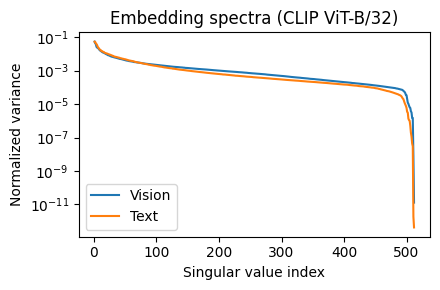

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(4.5, 3))
for s, lab in [(sV, 'Vision'), (sT, 'Text')]:
    ev = s**2 / (s**2).sum()
    ax.plot(np.arange(1, len(ev) + 1), ev, label=lab)
ax.set_yscale('log'); ax.set_xlabel('Singular value index'); ax.set_ylabel('Normalized variance')
ax.legend(); ax.set_title('Embedding spectra (CLIP ViT-B/32)')
fig.tight_layout(); fig.savefig(f'{PROJECT}/figures/fig1_spectra.png', dpi=200)
plt.show()

Quantization Functions

In [ ]:
VISION_PREFIX = ('visual.',)
TEXT_PREFIX = ('transformer.', 'token_embedding', 'positional_embedding', 'ln_final', 'text_projection')

def tower_params(model, tower):
    pre = VISION_PREFIX if tower == 'vision' else TEXT_PREFIX
    return {n: p for n, p in model.named_parameters() if n.startswith(pre) and p.ndim >= 2}  # skips LayerNorm/biases/logit_scale

@torch.no_grad()
def fake_quant_(w, bits):
    """Symmetric per-output-channel rounding to `bits` bits, stored back as floats."""
    qmax = 2 ** (bits - 1) - 1
    flat = w.reshape(w.shape[0], -1)
    scale = (flat.abs().amax(dim=1, keepdim=True) / qmax).clamp_min(1e-12)
    w.copy_(((flat / scale).round().clamp_(-qmax, qmax) * scale).reshape(w.shape))

@torch.no_grad()
def set_tower(model, orig, bits=None):
    """Restore the tower's original weights, then quantize to `bits` if given."""
    for n, p in model.named_parameters():
        if n in orig:
            p.copy_(orig[n])
            if bits is not None: fake_quant_(p, bits)

Parameter Sweep

In [ ]:
BITS = [8, 6, 5, 4, 3, 2]
results = {'vision': {}, 'text': {}}

for tower in ['vision', 'text']:
    orig = {n: p.detach().clone() for n, p in tower_params(model, tower).items()}
    for b in BITS:
        set_tower(model, orig, b)
        if tower == 'vision':               # only the image side changes; reuse cached T
            r = recall_at_k(embed_images(model, files), T, txt2img)
        else:                               # only the text side changes; reuse cached V
            r = recall_at_k(V, embed_texts(model, texts), txt2img)
        results[tower][b] = r
        print(tower, b, {k: round(v, 1) for k, v in r.items()})
        json.dump(results, open(f'{PROJECT}/results/quant_sweep.json', 'w'), indent=2)
    set_tower(model, orig, None)            # restore before moving to the other tower

vision 8 {'i2t_R@1': 56.8, 'i2t_R@5': 80.4, 'i2t_R@10': 87.3, 't2i_R@1': 38.8, 't2i_R@5': 64.7, 't2i_R@10': 74.7}
vision 6 {'i2t_R@1': 56.0, 'i2t_R@5': 80.1, 'i2t_R@10': 87.2, 't2i_R@1': 38.6, 't2i_R@5': 64.4, 't2i_R@10': 74.5}
vision 5 {'i2t_R@1': 53.2, 'i2t_R@5': 78.3, 'i2t_R@10': 85.7, 't2i_R@1': 36.8, 't2i_R@5': 62.7, 't2i_R@10': 73.0}
vision 4 {'i2t_R@1': 29.5, 'i2t_R@5': 53.4, 'i2t_R@10': 63.5, 't2i_R@1': 22.9, 't2i_R@5': 44.7, 't2i_R@10': 56.1}
vision 3 {'i2t_R@1': 0.0, 'i2t_R@5': 0.1, 'i2t_R@10': 0.3, 't2i_R@1': 0.1, 't2i_R@5': 0.6, 't2i_R@10': 1.2}
vision 2 {'i2t_R@1': 0.0, 'i2t_R@5': 0.1, 'i2t_R@10': 0.2, 't2i_R@1': 0.0, 't2i_R@5': 0.1, 't2i_R@10': 0.2}
text 8 {'i2t_R@1': 56.3, 'i2t_R@5': 80.2, 'i2t_R@10': 87.6, 't2i_R@1': 38.6, 't2i_R@5': 64.8, 't2i_R@10': 74.6}
text 6 {'i2t_R@1': 56.2, 'i2t_R@5': 80.1, 'i2t_R@10': 87.5, 't2i_R@1': 38.3, 't2i_R@5': 64.1, 't2i_R@10': 74.1}
text 5 {'i2t_R@1': 55.0, 'i2t_R@5': 78.9, 'i2t_R@10': 86.8, 't2i_R@1': 37.8, 't2i_R@5': 63.7, 't2i_R@10'

In [ ]:
print(np.abs(embed_texts(model, texts[:500]) - T[:500]).max())   # should be tiny (~1e-5)
print(np.abs(embed_images(model, files[:200]) - V[:200]).max())  # should be tiny

0.0
1.1175871e-06


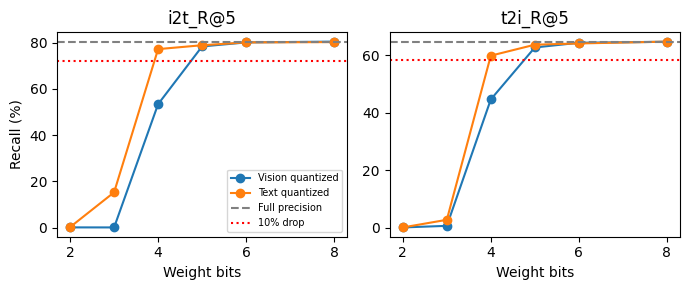

vision i2t_R@5 collapse at 4 bits
vision t2i_R@5 collapse at 4 bits
text i2t_R@5 collapse at 3 bits
text t2i_R@5 collapse at 3 bits


In [ ]:
import matplotlib.pyplot as plt
base = recall_at_k(V, T, txt2img)

fig, axes = plt.subplots(1, 2, figsize=(7, 3), sharex=True)
for ax, m in zip(axes, ['i2t_R@5', 't2i_R@5']):
    for tower, lab in [('vision', 'Vision quantized'), ('text', 'Text quantized')]:
        ax.plot(BITS, [results[tower][b][m] for b in BITS], marker='o', label=lab)
    ax.axhline(base[m], ls='--', c='gray', label='Full precision')
    ax.axhline(0.9 * base[m], ls=':', c='red', label='10% drop')
    ax.set_xlabel('Weight bits'); ax.set_title(m); ax.invert_xaxis()
axes[0].set_ylabel('Recall (%)'); axes[0].legend(fontsize=7)
fig.tight_layout(); fig.savefig(f'{PROJECT}/figures/fig2_quant.png', dpi=200); plt.show()

for tower in results:
    for m in ['i2t_R@5', 't2i_R@5']:
        hit = [b for b in BITS if results[tower][b][m] < 0.9 * base[m]]
        print(tower, m, 'collapse at', hit[0] if hit else 'not reached in sweep', 'bits')

vision collapses at 4 bits and text at 3 bits, which is roughly 8× versus 10.7× compression from fp32. Based on the magnitudes we can see that at 4 bits, vision has lost about a third of its recall, and text has lost just 4–8%. At 3 bits, vision is completely dead and text is badly damaged but not fully gone. Vision is also slightly worse at 5 bits, so it’s more fragile at every level above where both fail completely.

Effective rank and uniformity pointed weakly to vision (the flatter spectrum), and that matches. Stable rank was a tie, so it predicted nothing.